In [3]:
!pip install pandas
!pip install seaborn
!pip install scikit_learn

In [4]:
import pandas as pd
import seaborn as sas
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score,  
)
import joblib
csv=pd.read_csv(r"C:\Users\user\Desktop\archive\creditcard.csv")
print(csv.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [5]:
#نفحص تطابق الاعمدة
csv.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
#نفحص القيم الفارغة
csv.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [5]:
#نفحص الان  الاعمدة
csv.duplicated().sum()

np.int64(1081)

In [8]:
#نتعامل مع التكرار بالحذف
csv=csv.drop_duplicates()
csv=csv.reset_index(drop=True)

In [9]:
#نفحص الان  الاعمدة
csv.duplicated().sum()

np.int64(0)

In [7]:
csv['Class'].value_counts()
#نلاحظ انه يوجد عدم توازن بالبيانات ويمكن ان يوثر على صحة التوقع

Class
0    284315
1       492
Name: count, dtype: int64

<Axes: >

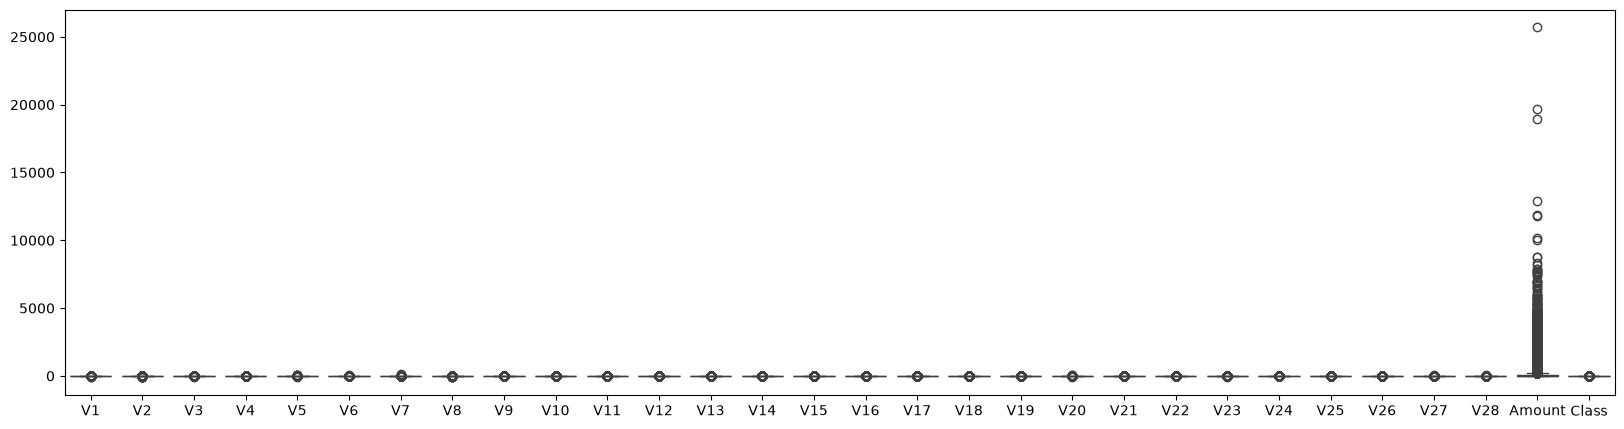

In [10]:
#الان بحاجة لنرى القيم الشاذة وذلك من خلال المخطط التالي
plt.figure(figsize=(20,5))
sas.boxplot(data=csv.drop(columns=['Time']))
#بسبب عدم توازن البيانات نلجا لاستبعاد عمود الوقت كي نرى بوضوع القيم الشاذة

In [10]:
#يجب معالجة القيم الشاذة
def outliers(df,columns):
    df_clean=df.copy()
    for col in columns:
        Q1=df_clean[col].quantile(0.25)
        Q3=df_clean[col].quantile(0.75)
        IQR=Q3-Q1
        loweer=Q1-1.5*IQR
        upper=Q3+1.5*IQR
        df_clean[col]=df_clean[col].clip(lower=loweer,upper=upper)
    return df_clean    

In [11]:
csv=outliers(csv,['Amount'])

<Axes: >

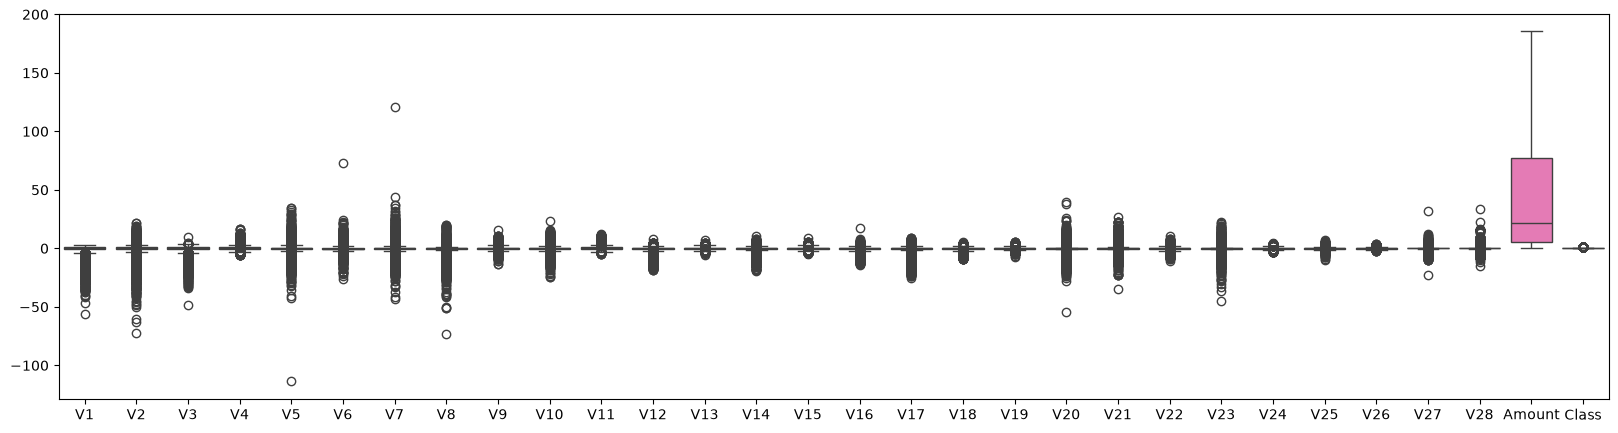

In [13]:
plt.figure(figsize=(20,5))
sas.boxplot(data=csv.drop(columns=['Time']))

In [14]:
#هنا الخدعة انه بسبب تفاوت القيم الكبير بالبداية لم نلاحظ ان مجال الاعمدة الصغير لديه قيم شاذة
v_cols=[col for col in csv.columns if col.startswith('V')]
csv=outliers(csv,v_cols)

<Axes: >

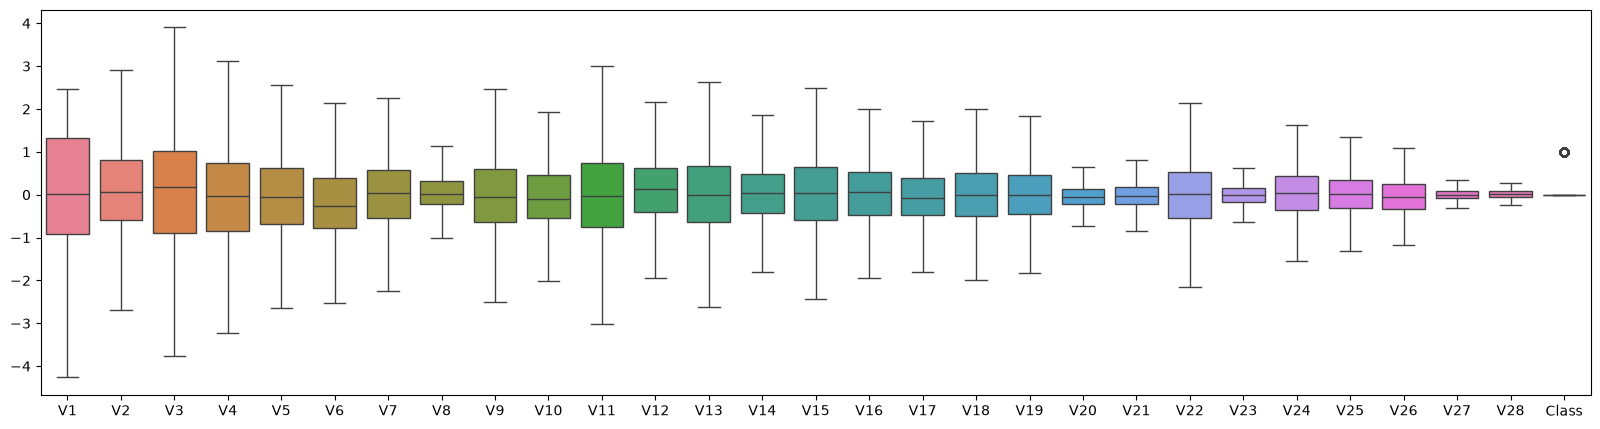

In [15]:
plt.figure(figsize=(20,5))
sas.boxplot(data=csv.drop(columns=['Time','Amount']))

In [12]:
X=csv.drop(columns=['Class'])
Y=csv['Class']
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=33,stratify=Y)

In [100]:
model=Pipeline([
   ( "scl",StandardScaler(),),
     ( "mod",RandomForestClassifier(n_estimators=100,random_state=33))
   # ("mod",LogisticRegression())
])


In [46]:
#لضمان البيانات غير المتوازنة class_weight='balanced'stratify=Yو

In [101]:
#تدريب النموذج والاختبار
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [102]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.77      0.85        98

    accuracy                           1.00     56962
   macro avg       0.98      0.88      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [103]:
print( confusion_matrix(y_test,y_pred))

[[56861     3]
 [   23    75]]


In [13]:
data = x_test.copy()
data["Class"] = y_test

fraud = data[data["Class"] == 1]
normal = data[data["Class"] == 0].sample(500, random_state=33)

sample = pd.concat([fraud, normal])
sample.to_csv("sample.csv", index=False)
print(sample.shape)

(595, 31)


In [104]:
#حفظ النموذج لكي لانحتاج تدريبه عند استخدامه بتطبيق حقيقي
joblib.dump(model, 'fraud_detection_model.pkl')
print("تم")

تم
